# Spoken Digit Recognition

Deep learning classification of spoken digits (0 to 9) from short audio recordings, using the Free Spoken Digit Dataset (FSDD) from MathWorks Signal Processing datasets.

## Dataset

The dataset contains **2,000 voice recordings** of the digits 0 to 9, spoken by **four speakers** ([MathWorks](https://www.mathworks.com/help/signal/ug/data-sets-for-signal-processing.html#mw_550b81db-14c1-4c65-84d0-d28574c8616a)). Each digit is represented by 200 recordings, so the classes are perfectly balanced.

| Property | Value |
|---|---|
| Recordings | 2,000 |
| Classes | 10 (digits 0 to 9) |
| Recordings per class | 200 |
| Speakers | 4 |
| Sample rate | 8 kHz |
| Bit depth | 16-bit |
| Channels | 1 (mono) |
| Duration | 0.14 s to 2.28 s (variable) |

Having several speakers introduces variation in accent and vocal characteristics, which makes the dataset suitable for building digit recognition models that generalise across different voices.

## Goal

Train a model that takes a raw audio recording as input and predicts which digit was spoken, and evaluate how well it generalises to unseen speakers.

## Imports and dataset

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import random
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Audio
import librosa
import librosa.display
import soundfile as sf
from IPython.display import Audio, display

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchaudio
import torchaudio.transforms as T

# Splitting and evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tqdm.auto import tqdm

In [2]:
import urllib.request
import zipfile

data_url = "https://ssd.mathworks.com/supportfiles/audio/FSDD.zip"
download_folder = Path("data") / "FSDD"
zip_file = download_folder / "FSDD.zip"

# Check if data set already exists. Otherwise, download it and unzip
if not download_folder.exists():
    download_folder.mkdir(parents=True)
    # Download data set
    urllib.request.urlretrieve(data_url, zip_file)
    with zipfile.ZipFile(zip_file) as zf:
        zf.extractall(download_folder)

print(download_folder.resolve())

/Users/gabrielaslomiany/PycharmProjects/Grey_Matter_Multiplication/Spoken Digit Recognition/data/FSDD


In [3]:
# use gpu if it's available if not cpu which is much slower
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
DATA_DIR = Path("data/FSDD")

records = []
for path in sorted(DATA_DIR.rglob("*.wav")):
    digit, speaker, _ = path.stem.split("_")
    info = sf.info(path)
    records.append({
        "path": str(path),
        "digit": int(digit),
        "speaker": speaker,
        "sample_rate": info.samplerate,
        "n_samples": info.frames,
        "duration [s]": info.frames / info.samplerate,
    })

df = pd.DataFrame(records)
print(df.shape)
df.head()

(2000, 6)


,path,digit,speaker,sample_rate,n_samples,duration [s]
0,data/FSDD/FSDD/recordings/0_jackson_0.wav,0,jackson,8000,5148,0.643500
1,data/FSDD/FSDD/recordings/0_jackson_1.wav,0,jackson,8000,4261,0.532625
2,data/FSDD/FSDD/recordings/0_jackson_10.wav,0,jackson,8000,5451,0.681375
3,data/FSDD/FSDD/recordings/0_jackson_11.wav,0,jackson,8000,4914,0.614250
4,data/FSDD/FSDD/recordings/0_jackson_12.wav,0,jackson,8000,4087,0.510875


- **`sample_rate`**: how many amplitude measurements are taken per second, in hertz (Hz); FSDD uses 8,000 Hz.
- **`n_samples`**: the total number of amplitude measurements in the recording, i.e. the length of the signal array.
- **`duration`**: how long the recording lasts, in seconds, calculated as $\text{duration} = \dfrac{n_{\text{samples}}}{\text{sample\_rate}}$.

## Data sanity check before EDA

- 200 per digit: each digit 0 to 9 should have exactly 200 recordings, so the classes are balanced. If one digit had far fewer, the model would be biased against it.
- How many per speaker: if one speaker has many more recordings than the others, the model may learn that voice best, and this also matters for speaker-based split.
- All at 8 kHz: every file should have the same sample rate. If one were 16 kHz, its spectrogram would look stretched and not comparable to the others.
- All mono: every file should have one audio channel. A stereo file would have two channels and a different array shape, which would break pipeline.


In [5]:
print(f'Recordings per digit: {df["digit"].value_counts().sort_index()}')

Recordings per digit: digit
0    200
1    200
2    200
3    200
4    200
5    200
6    200
7    200
8    200
9    200
Name: count, dtype: int64


In [6]:
print(f'Recordings per speaker: {df["speaker"].value_counts()}')

Recordings per speaker: speaker
jackson     500
nicolas     500
theo        500
yweweler    500
Name: count, dtype: int64


In [7]:
# digits per speaker
print(pd.crosstab(df["speaker"], df["digit"]))

digit      0   1   2   3   4   5   6   7   8   9
speaker                                         
jackson   50  50  50  50  50  50  50  50  50  50
nicolas   50  50  50  50  50  50  50  50  50  50
theo      50  50  50  50  50  50  50  50  50  50
yweweler  50  50  50  50  50  50  50  50  50  50


In [8]:
# expect [8000]
print(df["sample_rate"].unique())

[8000]


## EDA

### Digit audio display

In [16]:
path = df.loc[df["digit"] == 0, "path"].iloc[0]
print(path)
Audio(path)

data/FSDD/FSDD/recordings/0_jackson_0.wav


In [10]:
y, sr = librosa.load(path, sr=None)
print(y.shape, sr)
Audio(y, rate=sr)

(5148,) 8000


### Waveforms per digit

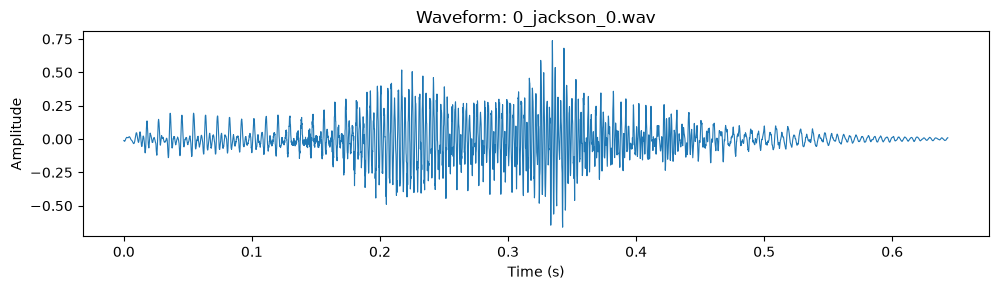

In [11]:
t = np.arange(len(y)) / sr

plt.figure(figsize=(10, 3))
plt.plot(t, y, linewidth=0.8)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title(f"Waveform: {path.split('/')[-1]}")
plt.tight_layout()
plt.show()

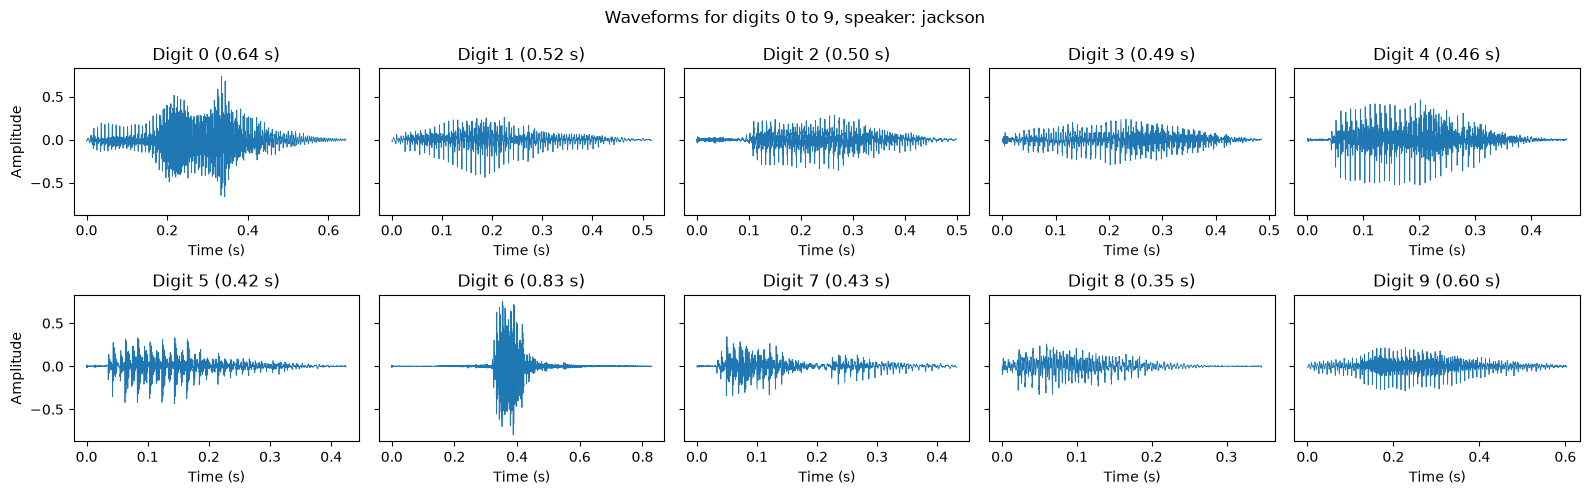

In [12]:
speaker = "jackson"
fig, axes = plt.subplots(2, 5, figsize=(16, 5), sharey=True)

for digit, ax in zip(range(10), axes.flat):
    path = df.loc[(df["speaker"] == speaker) & (df["digit"] == digit), "path"].iloc[0]
    y, sr = librosa.load(path, sr=None)
    t = np.arange(len(y)) / sr

    ax.plot(t, y, linewidth=0.6)
    ax.set_title(f"Digit {digit} ({len(y) / sr:.2f} s)")
    ax.set_xlabel("Time (s)")

axes[0, 0].set_ylabel("Amplitude")
axes[1, 0].set_ylabel("Amplitude")
fig.suptitle(f"Waveforms for digits 0 to 9, speaker: {speaker}")
plt.tight_layout()
plt.show()